<a href="https://colab.research.google.com/github/ponnivalavanponnivalavan608-lang/AI_Caption_Genarator/blob/main/AI_Image_Caption_Generator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🖼️ AI Image Caption Generator
**Goal:** Upload an image and let a pre-trained vision-language AI model understand it and write a human-readable caption.

**Pipeline**
1. Upload one or more images
2. **BLIP** (vision-language model) generates captions describing the objects and activities
3. **DETR** (object detection model) finds and labels the main objects
4. Display the image with its caption and detected objects
5. Export all results to CSV

**Models used (both pre-trained, no training needed)**
- `Salesforce/blip-image-captioning-base` → image → caption
- `facebook/detr-resnet-50` → image → objects with bounding boxes

## 1. Import libraries
Colab already includes everything needed, so **no pip install is required**. This avoids the package-version crashes.

In [ ]:
import os, io, requests
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from transformers import BlipProcessor, BlipForConditionalGeneration, pipeline

device = "cuda" if torch.cuda.is_available() else "cpu"
print("✅ Libraries ready | Running on:", device.upper())

✅ Libraries ready | Running on: CPU


## 2. Load the pre-trained models
The first run downloads the models (about 1 GB in total), so wait for it to finish.

In [ ]:
# --- Vision-language model for captions (BLIP) ---
blip_name = "Salesforce/blip-image-captioning-base"
processor = BlipProcessor.from_pretrained(blip_name)
caption_model = BlipForConditionalGeneration.from_pretrained(blip_name).to(device)
caption_model.eval()
print("✅ BLIP caption model loaded")

# --- Object detection model (DETR) ---
try:
    detector = pipeline("object-detection", model="facebook/detr-resnet-50",
                        revision="no_timm", device=0 if device == "cuda" else -1)
    print("✅ DETR object detector loaded")
except Exception as e:
    detector = None
    print("⚠️ Object detector could not be loaded. Captions will still work.\n", e)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

...

✅ BLIP caption model loaded


model.safetensors: reconstructing file:   0%|          |  0.00B /  990MB            

model.safetensors: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/6.60k [00:00<?, ?B/s]

⚠️ Object detector could not be loaded. Captions will still work.
 Validation error for field 'dilation':
    TypeError: Field 'dilation' expected bool, got NoneType (value: None)


## 3. Upload images
Select one or more images (`.jpg`, `.jpeg`, `.png`). If you skip the upload, **sample images** are downloaded automatically.

In [ ]:
from google.colab import files
uploaded = files.upload()
print(f"\n📂 {len(uploaded)} file(s) uploaded")

Saving sample_astronaut.jpg.jpeg to sample_astronaut.jpg.jpeg
Saving sample_coffee.jpg.jpeg to sample_coffee.jpg.jpeg
Saving sample_rocket.jpg.jpeg to sample_rocket.jpg.jpeg
Saving sample_flower.jpg.jpeg to sample_flower.jpg.jpeg
Saving sample_china_temple.jpg.jpeg to sample_china_temple.jpg.jpeg

📂 5 file(s) uploaded


## 4. Load the images

In [ ]:
images = {}
for name, data in uploaded.items():
    try:
        images[name] = Image.open(io.BytesIO(data)).convert("RGB")
    except Exception as e:
        print(f"⚠️ Skipped {name}: not a valid image ({e})")

# ---- Fallback: sample images from the COCO dataset ----
if not images:
    print("No valid uploads found → downloading SAMPLE images for demo.\n")
    sample_urls = {
        "sample_cats.jpg":   "http://images.cocodataset.org/val2017/000000039769.jpg",
        "sample_room.jpg":   "http://images.cocodataset.org/val2017/000000000139.jpg",
        "sample_bedroom.jpg": "http://images.cocodataset.org/val2017/000000000632.jpg",
    }
    for n, u in sample_urls.items():
        try:
            r = requests.get(u, timeout=20)
            images[n] = Image.open(io.BytesIO(r.content)).convert("RGB")
        except Exception as e:
            print(f"⚠️ Could not download {n}: {e}")

print(f"✅ {len(images)} image(s) ready")
for n, im in images.items():
    print(f" - {n}: {im.size[0]}x{im.size[1]} px")

✅ 5 image(s) ready
 - sample_astronaut.jpg.jpeg: 512x512 px
 - sample_coffee.jpg.jpeg: 600x400 px
 - sample_rocket.jpg.jpeg: 640x427 px
 - sample_flower.jpg.jpeg: 640x427 px
 - sample_china_temple.jpg.jpeg: 640x427 px


## 5. Caption and object-detection functions

In [ ]:
def generate_caption(image, prompt=None, num_captions=1, max_new_tokens=40):
    """Generate caption(s). prompt (optional) starts the sentence, e.g. 'a photo of'."""
    if prompt:
        inputs = processor(image, prompt, return_tensors="pt").to(device)
    else:
        inputs = processor(image, return_tensors="pt").to(device)
    with torch.no_grad():
        out = caption_model.generate(
            **inputs, max_new_tokens=max_new_tokens,
            num_beams=max(5, num_captions), num_return_sequences=num_captions,
            repetition_penalty=1.3, early_stopping=True)
    caps = [processor.decode(o, skip_special_tokens=True).strip() for o in out]
    return caps if num_captions > 1 else caps[0]

def detect_objects(image, threshold=0.85):
    """Return a list of detected objects with confidence and boxes."""
    if detector is None:
        return []
    results = detector(image)
    return [r for r in results if r["score"] >= threshold]

def summarize_objects(objs):
    if not objs:
        return "none detected"
    counts = pd.Series([o["label"] for o in objs]).value_counts()
    return ", ".join(f"{c} {l}" if c > 1 else l for l, c in counts.items())

print("✅ Functions ready")

✅ Functions ready


## 6. Show the image with its caption and detected objects

/tmp/ipykernel_2701/2756866842.py:15: UserWarning: Glyph 128221 (\N{MEMO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128221 (\N{MEMO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


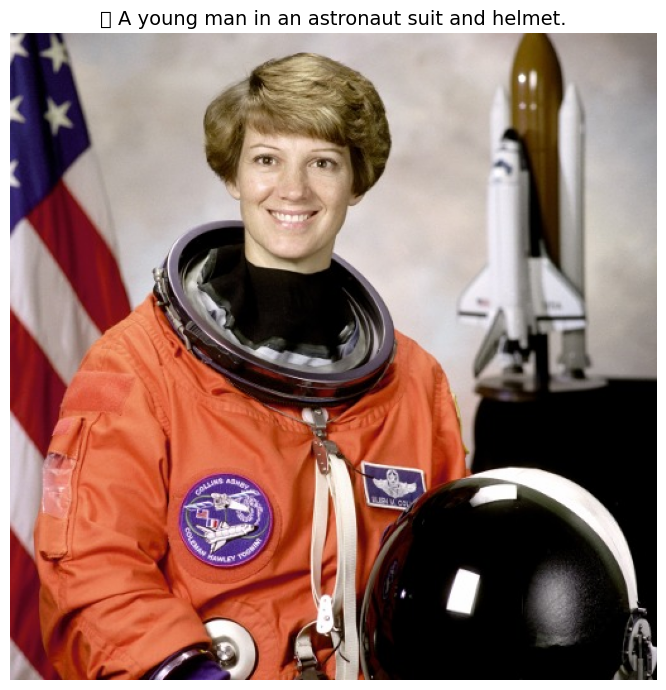

🖼️  Image   : sample_astronaut.jpg.jpeg
📝 Caption : A young man in an astronaut suit and helmet.
🔎 Objects : none detected



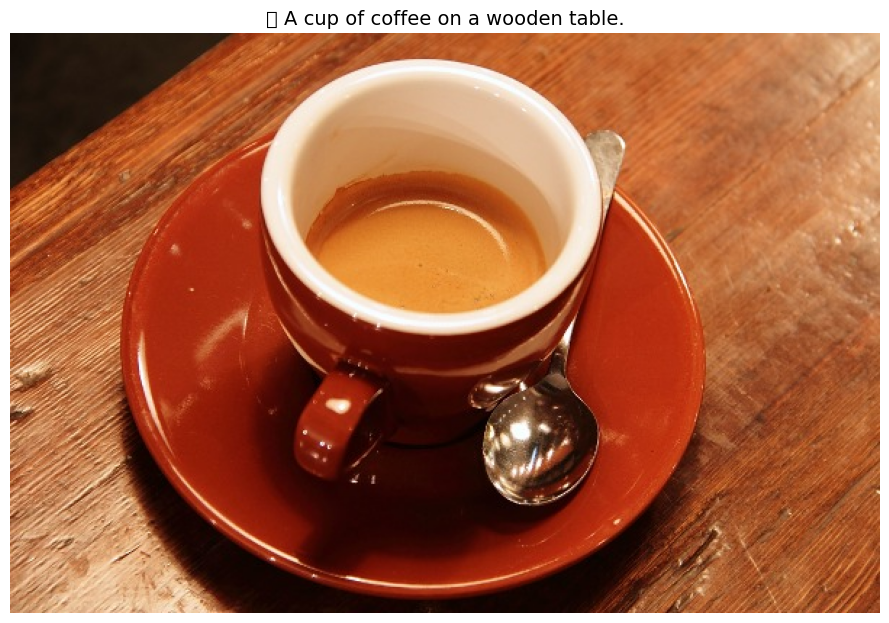

🖼️  Image   : sample_coffee.jpg.jpeg
📝 Caption : A cup of coffee on a wooden table.
🔎 Objects : none detected



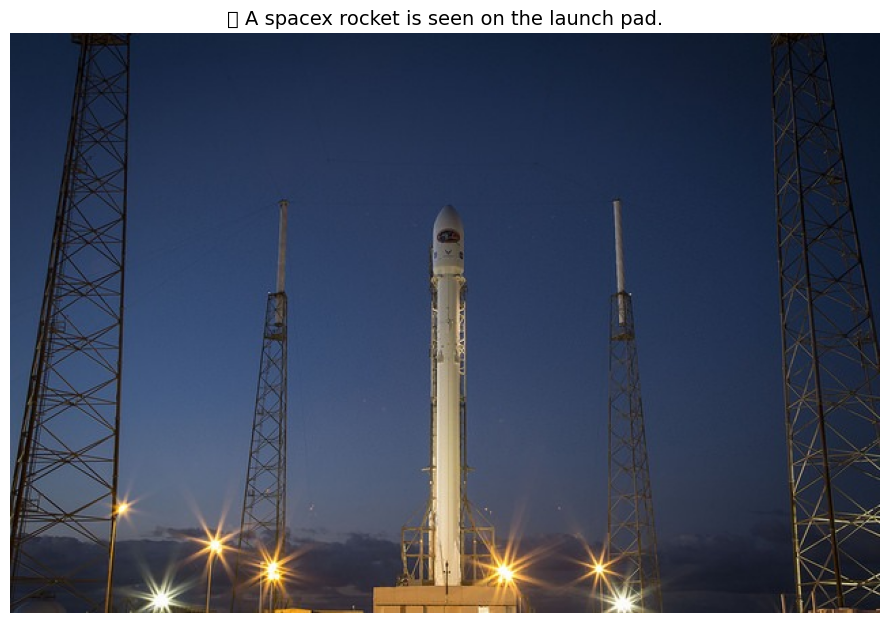

🖼️  Image   : sample_rocket.jpg.jpeg
📝 Caption : A spacex rocket is seen on the launch pad.
🔎 Objects : none detected



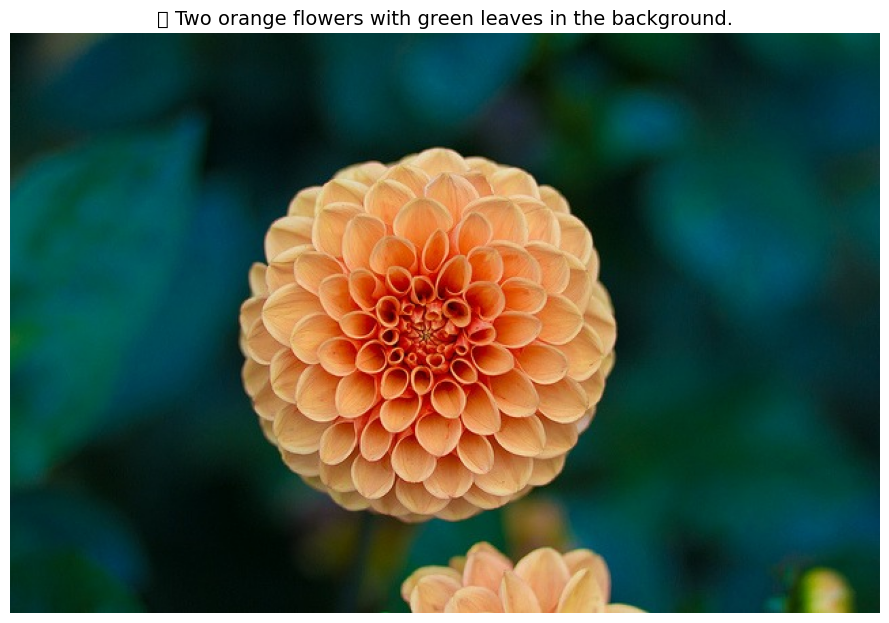

🖼️  Image   : sample_flower.jpg.jpeg
📝 Caption : Two orange flowers with green leaves in the background.
🔎 Objects : none detected



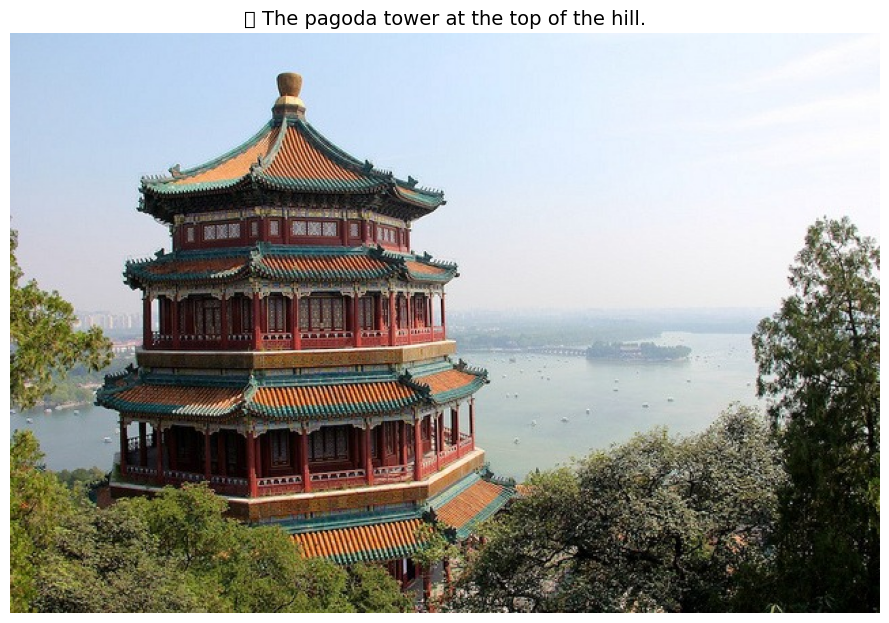

🖼️  Image   : sample_china_temple.jpg.jpeg
📝 Caption : The pagoda tower at the top of the hill.
🔎 Objects : none detected



In [ ]:
def show_result(name, image):
    caption = generate_caption(image)
    objs = detect_objects(image)

    fig, ax = plt.subplots(figsize=(9, 7))
    ax.imshow(image)
    ax.axis("off")
    for o in objs:
        b = o["box"]
        ax.add_patch(patches.Rectangle((b["xmin"], b["ymin"]), b["xmax"] - b["xmin"],
                     b["ymax"] - b["ymin"], fill=False, edgecolor="lime", linewidth=2))
        ax.text(b["xmin"], max(b["ymin"] - 4, 8), f'{o["label"]} {o["score"]:.0%}',
                color="black", fontsize=9, backgroundcolor="lime")
    ax.set_title(f"📝 {caption.capitalize()}.", fontsize=14, wrap=True)
    plt.tight_layout()
    plt.show()

    print(f"🖼️  Image   : {name}")
    print(f"📝 Caption : {caption.capitalize()}.")
    print(f"🔎 Objects : {summarize_objects(objs)}\n")
    return caption, objs

all_results = []
for name, img in images.items():
    cap, objs = show_result(name, img)
    all_results.append({"Image": name, "Caption": cap.capitalize() + ".",
                        "Objects Detected": summarize_objects(objs),
                        "Object Count": len(objs)})

## 7. Multiple caption options and guided captions
The model can suggest several alternative captions, and a text prompt can steer the description.

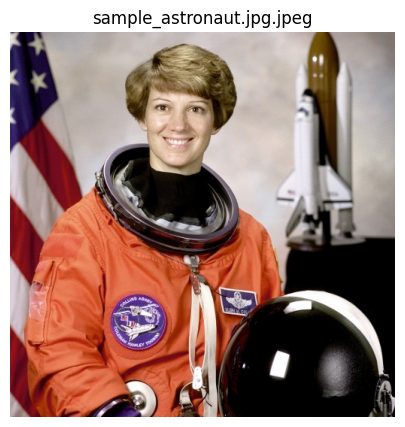

🔹 3 alternative captions:
   1. A young man in an astronaut suit and helmet.
   2. A young man in an orange astronaut suit and helmet.
   3. A woman in an orange astronaut suit and helmet.

🔹 Guided captions (prompt-based):
   [a photography of] → a photography of an astronaut in front of an american flag
   [a picture showing] → a picture showing a woman in an astronaut suit and helmet
   [this is an image of] → this is an image of a woman in an astronaut suit


In [ ]:
first_name = list(images.keys())[0]
img = images[first_name]

plt.figure(figsize=(6, 5)); plt.imshow(img); plt.axis("off"); plt.title(first_name); plt.show()

print("🔹 3 alternative captions:")
for i, c in enumerate(generate_caption(img, num_captions=3), 1):
    print(f"   {i}. {c.capitalize()}.")

print("\n🔹 Guided captions (prompt-based):")
for p in ["a photography of", "a picture showing", "this is an image of"]:
    print(f"   [{p}] → {generate_caption(img, prompt=p)}")

## 8. Results table and export

In [ ]:
results_df = pd.DataFrame(all_results)
results_df.index = results_df.index + 1
display(results_df)

results_df.to_csv("image_caption_results.csv", index_label="No")
files.download("image_caption_results.csv")
print("📥 Saved as image_caption_results.csv")

,Image,Caption,Objects Detected,Object Count
1,sample_astronaut.jpg.jpeg,A young man in an astronaut suit and helmet.,none detected,0
2,sample_coffee.jpg.jpeg,A cup of coffee on a wooden table.,none detected,0
3,sample_rocket.jpg.jpeg,A spacex rocket is seen on the launch pad.,none detected,0
4,sample_flower.jpg.jpeg,Two orange flowers with green leaves in the ba...,none detected,0
5,sample_china_temple.jpg.jpeg,The pagoda tower at the top of the hill.,none detected,0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

📥 Saved as image_caption_results.csv


## 9. Optional: caption any image from a URL

In [ ]:
def caption_from_url(url):
    r = requests.get(url, timeout=20)
    im = Image.open(io.BytesIO(r.content)).convert("RGB")
    return show_result("url_image", im)

# Example (uncomment to try):
# caption_from_url("http://images.cocodataset.org/val2017/000000039769.jpg")

## 📌 Summary / Conclusion
- A pre-trained **vision-language model (BLIP)** converts an uploaded image into a natural-language caption.
- A pre-trained **object detector (DETR)** finds the main objects and draws labelled boxes.
- The image, caption and objects are displayed together, and results are exported to CSV.

**Limitations & future work:** captions can miss fine details or make mistakes on unusual scenes; add a larger model (BLIP-2), multilingual captions, text-to-speech for accessibility, and a Gradio web interface.